# Actividad 3: Prototipo con transferencia de aprendizaje y *fine-tuning*

## Estudiantes
- Luis Jorge García
- Luis Eduardo Uribe
- Felipe Barreto Patiño

**Problema:** Dado un recorte pequeño centrado en un punto anotado de un jugador de pádel, clasificar **qué tipo de keypoint es**: `hombro`, `codo`, `muñeca`, `raqueta` o `cabeza` (5 clases). Es la pieza de reconocimiento local que alimenta el seguimiento de los 5 puntos por jugador del proyecto.

**Origen:** En la Unidad 2 (`notebooks/unidad_2/actividad_3_clasificacion_visual_cnn.ipynb`) esta tarea se resolvió con una CNN entrenada **desde cero** y el *transfer learning* (ResNet18) solo se usó para regresar coordenadas. Este notebook extrae y formaliza la parte de transferencia de aprendizaje y la aplica a la clasificación, comparándola contra esa CNN como **línea base** (configuración de referencia), con la misma partición y los mismos datos.

| Criterio de la rúbrica | Checkpoints |
|---|---|
| Preparación de imágenes y tensores | 1 a 4 |
| Implementación de *transfer learning* | 6 |
| Monitoreo y optimización del entrenamiento | 5, 7, 8, 9 |
| Evaluación de desempeño multiclase | 10 |
| Interpretación y comunicación técnica | 11, 13 (y el reporte PDF) |

Diseñamos este notebook, de manera que cada checkpoint deja su resultado visible (tabla, figura o *print*) antes de pasar al siguiente.

## Checkpoint 0: Configuración, semillas y dispositivo

In [19]:
import os, re, json, random, time, copy, math
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.transforms import v2 as T

from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_recall_fscore_support)
from scipy.stats import binomtest

SEED = 42

def seed_everything(seed=SEED):
    """Semillas de todas las fuentes de azar + cuDNN determinista: re-ejecutar da los mismos numeros."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()

def find_repo_root(start=None):
    p = Path(start or Path.cwd())
    for _ in range(6):
        if (p / "data.yaml").exists():
            return p
        p = p.parent
    raise FileNotFoundError("No se encontro data.yaml subiendo desde " + str(start))

ROOT = find_repo_root()
DATA_DIR = ROOT / "data" / "Padel_an_2-6"
PROC = ROOT / "data" / "processed"
FIGS = ROOT / "report" / "figs_transfer"
FIGS.mkdir(parents=True, exist_ok=True)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# Orden real de los keypoints en las etiquetas
KP_NAMES = ["hombro", "codo", "muneca", "raqueta", "cabeza"]
N_CLASSES = len(KP_NAMES)

def savefig(name):
    plt.savefig(FIGS / f"{name}.png", dpi=150, bbox_inches="tight")

print("ROOT:", ROOT)
print("Dispositivo:", device, f"({torch.cuda.get_device_name(0)})" if device.type == "cuda" else "")
print("torch", torch.__version__)

ROOT: c:\Users\luisj\OneDrive\Documentos\Maestria Inteligencia Artificial\Tercer Semestre\Primer Ciclo\Tecnicas_Avanzadas_Modelado_En_IA\Unidad_2\padel-impact-position-detection
Dispositivo: cuda (NVIDIA GeForce RTX 4070 Laptop GPU)
torch 2.14.1+cu132


## Checkpoint 1: Carga del dataset y parsing de anotaciones

Imágenes: frames de video de pádel grabado por el autor, con los 5 keypoints por jugador **anotados manualmente** en Roboflow (proyecto `padel_an_2`, versión 6) y exportados en formato YOLO-pose. Cada línea de un `.txt` es un jugador: `clase cx cy w h` (bbox normalizado) y 5 × `(x, y, v)`.

La versión `yolov5` del export es la correcta (la exportación nativa de Roboflow traía valores centinela `2.0` desplazados entre ejes.). 

Si las imágenes no están en disco, se descargan con la API de Roboflow usando la variable de entorno `ROBOFLOW_API_KEY`.

In [20]:
def has_images():
    return any(next((DATA_DIR / s / "images").glob("*.jpg"), None) for s in ["train", "valid", "test"]
               if (DATA_DIR / s / "images").exists())

if not has_images():
    from roboflow import Roboflow
    key = os.environ.get("ROBOFLOW_API_KEY")
    if not key:
        raise RuntimeError("Faltan las imagenes del dataset: define ROBOFLOW_API_KEY y vuelve a ejecutar.")
    Roboflow(api_key=key).workspace("padel1s-workspace").project("padel_an_2").version(6) \
        .download("yolov5", location=str(DATA_DIR), overwrite=True)

RALLY_RE = re.compile(r"^(.*_mp4)-(\d+)_jpg")

def parse_label_file(path):
    persons = []
    for line in open(path):
        tok = line.split()
        if tok:
            vals = list(map(float, tok))
            persons.append((vals[1:5], vals[5:20]))
    return persons

rows = []
for orig_split in ["train", "valid", "test"]:  # se juntan: el split de Roboflow mezcla rallies
    for img_path in sorted((DATA_DIR / orig_split / "images").glob("*.jpg")):
        lbl = DATA_DIR / orig_split / "labels" / (img_path.stem + ".txt")
        if not lbl.exists():
            continue
        m = RALLY_RE.match(img_path.name)
        for p_idx, ((cx, cy, w, h), kpts) in enumerate(parse_label_file(lbl)):
            rows.append(dict(image_id=img_path.stem, image_path=str(img_path),
                             rally_id=m.group(1) if m else "unknown", person_idx=p_idx,
                             cx=cx, cy=cy, w=w, h=h, kpts=kpts))

df = pd.DataFrame(rows)
img0 = Image.open(df.image_path.iloc[0])
print(f"Imagenes: {df.image_id.nunique()} | jugadores anotados: {len(df)} | rallies: {df.rally_id.nunique()}")
print("Tamano de imagen:", img0.size, "| modo:", img0.mode)
print("Jugadores por imagen:", df.groupby("image_id").size().value_counts().sort_index().to_dict())

Imagenes: 333 | jugadores anotados: 1150 | rallies: 35
Tamano de imagen: (640, 640) | modo: RGB
Jugadores por imagen: {1: 13, 2: 36, 3: 71, 4: 213}


## Checkpoint 2: Particiones por rally y controles de fuga de información

Frames consecutivos de un mismo rally son casi idénticos. Si un rally aparece en *train* y en *test*,
el modelo se evalúa sobre imágenes que prácticamente ya vio, y la métrica queda inflada. 

Por esto mismo, la partición se hace **por grupo (rally)** con `GroupShuffleSplit` (70 / 15 / 15, semilla 42).

Se reutiliza exactamente la partición guardada en la Unidad 2 (`data/processed/image_splits.csv`),
para que la línea base y los modelos nuevos se comparen sobre los **mismos** datos. Controles:

1. Cada rally cae en un único split (aserción).
2. Ninguna imagen aparece en dos splits (aserción).
3. Las estadísticas de normalización y cualquier selección de hiperparámetros usan **solo** *train* y
   *valid*; *test* se toca una única vez, en el Checkpoint 10.

In [21]:
splits = pd.read_csv(PROC / "image_splits.csv")
df["split"] = df.image_id.map(dict(zip(splits.image_id, splits.split)))
assert df.split.notna().all(), "Hay imagenes sin split asignado"

# Control 1: un rally -> un split
assert (df.groupby("rally_id").split.nunique() == 1).all(), "Fuga: un rally aparece en mas de un split"
# Control 2: una imagen -> un split
assert (df.groupby("image_id").split.nunique() == 1).all(), "Fuga: una imagen aparece en mas de un split"
rallies = {s: set(df[df.split == s].rally_id) for s in ["train", "valid", "test"]}
assert not (rallies["train"] & rallies["valid"]) and not (rallies["train"] & rallies["test"]) \
    and not (rallies["valid"] & rallies["test"])
print("OK: sin rallies ni imagenes compartidas entre particiones.\n")

summary = df.groupby("split").agg(imagenes=("image_id", "nunique"), jugadores=("image_id", "size"),
                                  rallies=("rally_id", "nunique")).loc[["train", "valid", "test"]]
summary["% jugadores"] = (100 * summary.jugadores / summary.jugadores.sum()).round(1)
summary

OK: sin rallies ni imagenes compartidas entre particiones.



,imagenes,jugadores,rallies,% jugadores
split,,,,
train,204,682,24,59.3
valid,65,247,5,21.5
test,64,221,6,19.2


## Checkpoint 3: Construcción de la base de clasificación (un parche por keypoint)

Cada keypoint anotado con `v > 0` se convierte en una muestra. Un parche cuadrado centrado en el punto, con su tipo como etiqueta. El lado del parche es **proporcional al alto del jugador** (`0.5 × alto_bbox`, acotado a 24–90 px), para que un jugador cercano y uno lejano se encuadren de forma comparable.

Las clases quedan **balanceadas** (Aprox. 20 % cada una en los tres splits), así que la exactitud es interpretable y la línea base trivial (clase mayoritaria) ronda el 21 %.

In [22]:
PATCH_FRAC, MIN_PATCH, MAX_PATCH = 0.5, 24, 90

kpt_rows = []
for _, r in df.iterrows():
    for i in range(N_CLASSES):
        x, y, v = r.kpts[3 * i], r.kpts[3 * i + 1], r.kpts[3 * i + 2]
        if v > 0:
            kpt_rows.append(dict(image_path=r.image_path, image_id=r.image_id, rally_id=r.rally_id,
                                 split=r.split, x=x, y=y, bbox_h=r.h, label=i))
kpt_df = pd.DataFrame(kpt_rows)

counts = pd.crosstab(kpt_df.split, kpt_df.label).rename(columns=dict(enumerate(KP_NAMES)))
counts = counts.loc[["train", "valid", "test"], KP_NAMES]
counts["total"] = counts.sum(axis=1)
print("Parches por split y clase:")
print(counts)
print("\nProporcion por clase (%):")
print((100 * counts[KP_NAMES].div(counts.total, axis=0)).round(1))

Parches por split y clase:
label  hombro  codo  muneca  raqueta  cabeza  total
split                                              
train     679   667     648      657     682   3333
valid     236   233     212      208     247   1136
test      217   210     201      197     220   1045

Proporcion por clase (%):
label  hombro  codo  muneca  raqueta  cabeza
split                                       
train    20.4  20.0    19.4     19.7    20.5
valid    20.8  20.5    18.7     18.3    21.7
test     20.8  20.1    19.2     18.9    21.1


## Checkpoint 4: Tensores, normalización y aumentación estocástica

**Carga:** Las imágenes (640×640, RGB) se cargan una vez en memoria, cada parche se recorta al vuelo, de modo que la aumentación puede actuar **sobre el recorte** y no solo sobre un píxel ya fijo.

**Tamaño de entrada.**
- *Línea base:* 48×48.
- *ResNet18:* 112×112. La red reduce la resolución 32 veces. Con 48 px su último mapa sería de 2×2, y
  con 112 px es de 4×4, más cercano a la escala con que se aprendieron los filtros de ImageNet.

**Normalización.**
- *Línea base:* media y desviación por canal calculadas **solo con *train*** (sin fuga).
- *ResNet18:* media y desviación **de ImageNet**. Los pesos preentrenados esperan esa distribución de
  entrada; con otra, las activaciones de las primeras capas se desplazan y se pierde parte de lo
  transferido.

**Aumentación estocástica (solo en *train*).**

| Transformación | Rango | Por qué |
|---|---|---|
| Jitter de escala del recorte | ±15 % del lado | El tamaño aparente del keypoint cambia con la distancia a la cámara |
| Jitter de posición del recorte | ±10 % del lado | La anotación manual tiene unos píxeles de error |
| Flip horizontal | p = 0.5 | El tipo de keypoint no depende del lado del cuerpo |
| Rotación | ±12° | Brazos y raqueta en distintos ángulos |
| `ColorJitter` | brillo/contraste 0.3, saturación 0.2, tono 0.02 | Sol, sombra y distintas cámaras |

En *valid* y *test* el recorte es determinista (sin jitter), y sus tensores se calculan una sola vez.

In [23]:
IMAGES = {p: Image.open(p).convert("RGB") for p in kpt_df.image_path.unique()}
print(f"Imagenes en memoria: {len(IMAGES)}")

def crop_patch(row, out_size, rng=None):
    """Recorte cuadrado centrado en el keypoint; con `rng`, con jitter de escala y posicion."""
    im = IMAGES[row.image_path]
    W, H = im.size
    side = float(np.clip(row.bbox_h * H * PATCH_FRAC, MIN_PATCH, MAX_PATCH))
    px, py = row.x * W, row.y * H
    if rng is not None:
        side *= rng.uniform(0.85, 1.15)
        px += rng.uniform(-0.10, 0.10) * side
        py += rng.uniform(-0.10, 0.10) * side
    box = (px - side / 2, py - side / 2, px + side / 2, py + side / 2)  # fuera de la imagen: relleno negro
    return im.crop(box).resize((out_size, out_size), Image.BILINEAR)

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_kpt = kpt_df[kpt_df.split == "train"].reset_index(drop=True)
_sample = train_kpt.sample(600, random_state=SEED)
_pix = np.stack([np.asarray(crop_patch(r, 48), np.float32) / 255 for _, r in _sample.iterrows()])
TRAIN_MEAN, TRAIN_STD = _pix.reshape(-1, 3).mean(0).tolist(), _pix.reshape(-1, 3).std(0).tolist()
print("Normalizacion linea base (solo train):", np.round(TRAIN_MEAN, 3), np.round(TRAIN_STD, 3))
print("Normalizacion ResNet18 (ImageNet):    ", IMAGENET_MEAN, IMAGENET_STD)

AUGMENT = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(12),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.02),
])

class PatchDataset(Dataset):
    def __init__(self, frame, out_size, mean, std, train=False, seed=SEED):
        self.frame = frame.reset_index(drop=True)
        self.out_size, self.train = out_size, train
        self.norm = T.Normalize(mean, std)
        self.to_tensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
        self.rng = np.random.default_rng(seed)
        self.cache = None
        if not train:  # valid/test: recorte determinista, tensores calculados una sola vez
            self.cache = torch.stack([self._make(i) for i in range(len(self.frame))])

    def _make(self, i):
        row = self.frame.iloc[i]
        img = self.to_tensor(crop_patch(row, self.out_size, self.rng if self.train else None))
        if self.train:
            img = AUGMENT(img)
        return self.norm(img)

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        x = self.cache[i] if self.cache is not None else self._make(i)
        return x, int(self.frame.label.iloc[i])

def make_loaders(out_size, mean, std, batch_size=64):
    g = torch.Generator().manual_seed(SEED)
    parts = {s: kpt_df[kpt_df.split == s] for s in ["train", "valid", "test"]}
    return {
        "train": DataLoader(PatchDataset(parts["train"], out_size, mean, std, train=True), batch_size,
                            shuffle=True, generator=g),
        "valid": DataLoader(PatchDataset(parts["valid"], out_size, mean, std), batch_size),
        "test": DataLoader(PatchDataset(parts["test"], out_size, mean, std), batch_size),
    }

loaders_base = make_loaders(48, TRAIN_MEAN, TRAIN_STD)
loaders_tl = make_loaders(112, IMAGENET_MEAN, IMAGENET_STD)

xb, yb = next(iter(loaders_tl["train"]))
print(f"\nBatch ResNet18: x={tuple(xb.shape)} {xb.dtype}  y={tuple(yb.shape)} {yb.dtype}"
      f" | media={xb.mean():.2f} desv={xb.std():.2f} (normalizado ~ N(0,1))")
xb0, _ = next(iter(loaders_base["train"]))
print(f"Batch linea base: x={tuple(xb0.shape)}")

Imagenes en memoria: 333
Normalizacion linea base (solo train): [0.314 0.373 0.487] [0.156 0.167 0.218]
Normalizacion ResNet18 (ImageNet):     [0.485, 0.456, 0.406] [0.229, 0.224, 0.225]

Batch ResNet18: x=(64, 3, 112, 112) torch.float32  y=(64,) torch.int64 | media=-0.38 desv=0.99 (normalizado ~ N(0,1))
Batch linea base: x=(64, 3, 48, 48)


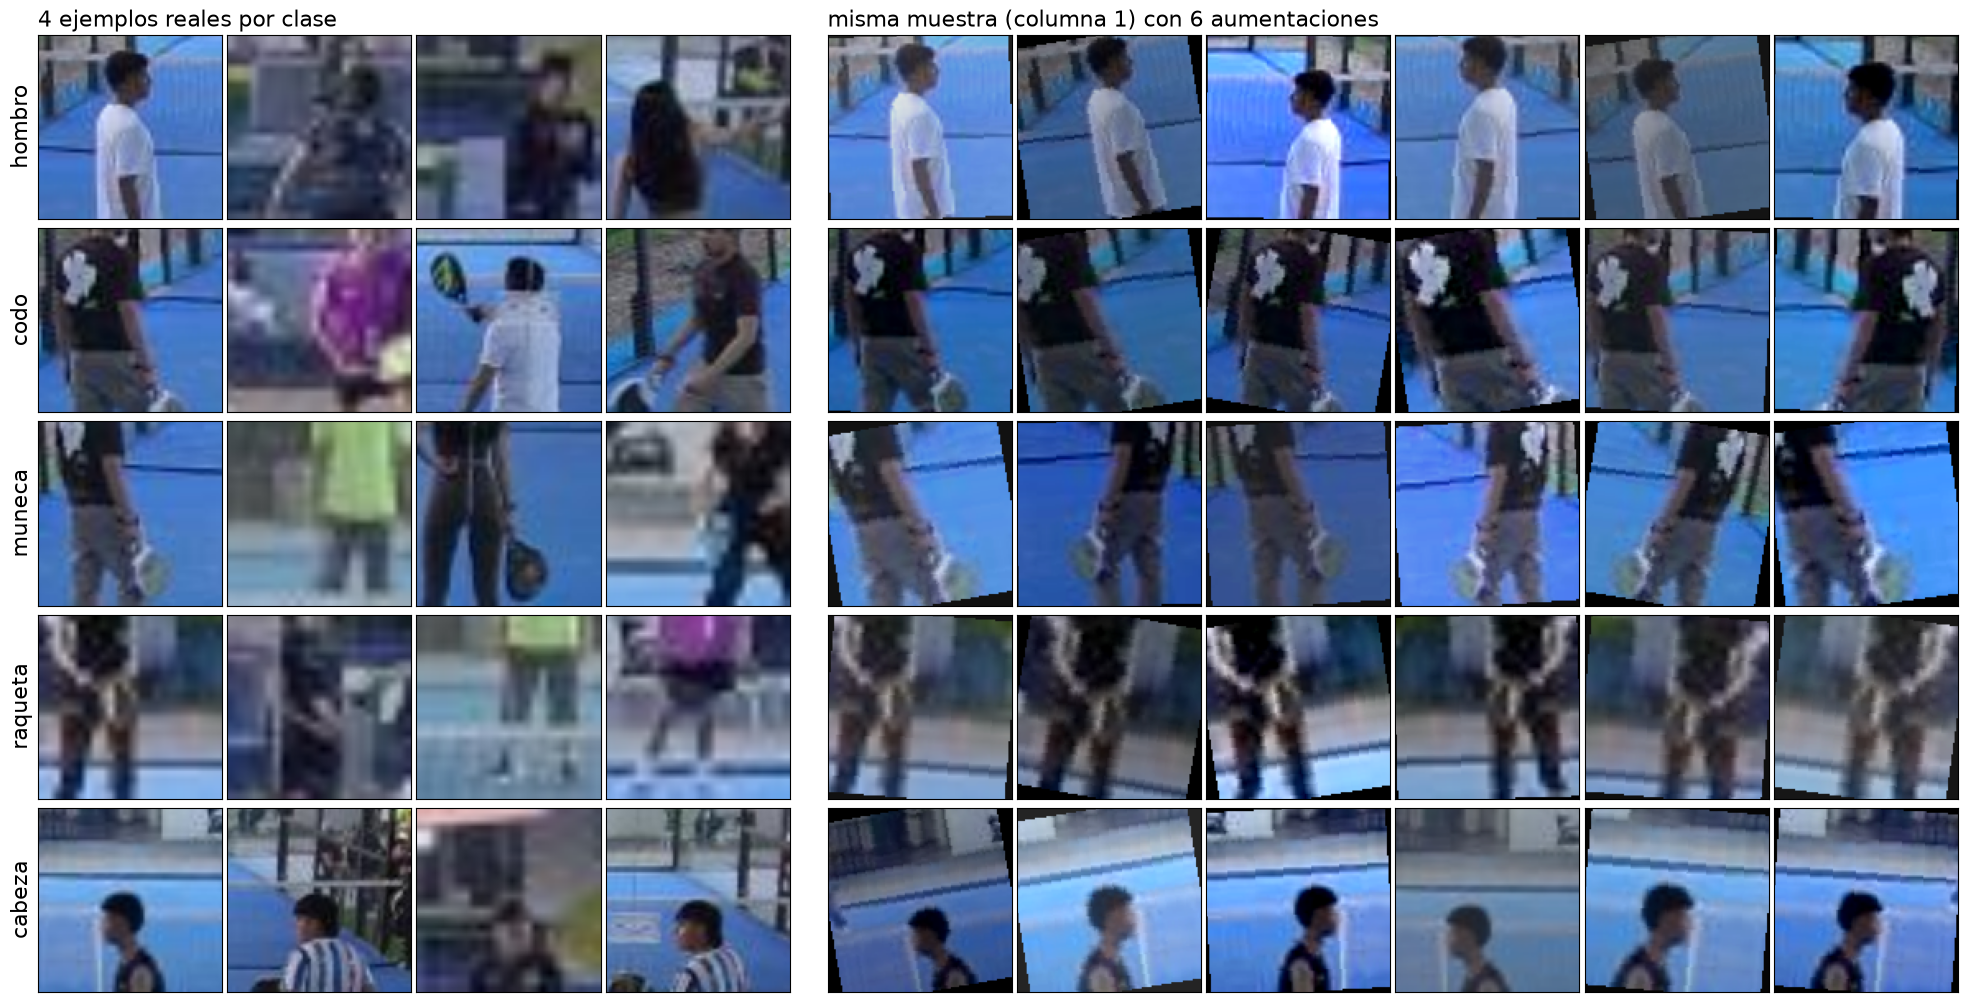

In [24]:
# Ejemplos por clase (fila) y la misma muestra bajo 6 aumentaciones aleatorias (derecha)
# Rejilla 5x10 con una columna angosta de separacion entre ejemplos reales y aumentaciones,
# margenes minimos y celdas cuadradas para que la figura ocupe todo el ancho.
fig = plt.figure(figsize=(20, 10.2))
gs = fig.add_gridspec(N_CLASSES, 11, width_ratios=[1] * 4 + [0.15] + [1] * 6,
                      wspace=0.03, hspace=0.04, left=0.035, right=0.995, top=0.945, bottom=0.005)
axes = np.array([[fig.add_subplot(gs[c, j if j < 4 else j + 1]) for j in range(10)]
                 for c in range(N_CLASSES)])
rng = np.random.default_rng(SEED)
for c, name in enumerate(KP_NAMES):
    sub = train_kpt[train_kpt.label == c].sample(4, random_state=SEED + c)
    for j, (_, row) in enumerate(sub.iterrows()):
        axes[c, j].imshow(crop_patch(row, 112))
    base_row = sub.iloc[0]
    for j in range(6):
        img = AUGMENT(T.ToImage()(crop_patch(base_row, 112, rng)))
        axes[c, 4 + j].imshow(img.permute(1, 2, 0).numpy())
    axes[c, 0].set_ylabel(name, fontsize=16)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_title("4 ejemplos reales por clase", loc="left", fontsize=16)
axes[0, 4].set_title("misma muestra (columna 1) con 6 aumentaciones", loc="left", fontsize=16)
savefig("cp4_parches_y_aumentacion"); plt.show()

## Checkpoint 5: Bucle de entrenamiento y línea base (CNN desde cero, Unidad 2)

Un único bucle de entrenamiento para todos los modelos, que garantiza que la comparación sea justa:

- **Pérdida:** entropía cruzada.
- **Métricas:** pérdida y exactitud de *train* y *valid* en cada época.
- **Parada temprana:** sobre la pérdida de *valid*, con paciencia y `min_delta`, restaurando el estado
  de la mejor época.
- **Programador de LR:** opcional.

Línea base: 3 bloques Conv–BN–ReLU, *Global Average Pooling*, `Dropout(0.3) -> Linear(64, 5)`, Adam con lr = 1e-3 y entradas de 48×48. Solo cambia la aumentación, que ahora es la misma para todos los modelos.

In [25]:
CRITERION = nn.CrossEntropyLoss()

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = CRITERION(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            tot_loss += loss.item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return tot_loss / n, correct / n

def fit(model, optimizer, loaders, max_epochs, patience, min_delta=1e-4, scheduler=None, tag=""):
    """Entrena con parada temprana sobre val_loss y restaura la mejor epoca. Devuelve el historial."""
    history, best = [], dict(loss=float("inf"), epoch=None, state=None)
    ref, stale, t0 = float("inf"), 0, time.time()
    for ep in range(1, max_epochs + 1):
        tr_l, tr_a = run_epoch(model, loaders["train"], optimizer)
        va_l, va_a = run_epoch(model, loaders["valid"])
        lr = optimizer.param_groups[-1]["lr"]
        if scheduler is not None:
            scheduler.step()
        history.append(dict(epoch=ep, train_loss=tr_l, train_acc=tr_a, val_loss=va_l, val_acc=va_a, lr=lr))
        if va_l < best["loss"]:
            best = dict(loss=va_l, epoch=ep, state=copy.deepcopy(model.state_dict()))
        if ref - va_l >= min_delta:
            ref, stale = va_l, 0
        else:
            stale += 1
        if ep == 1 or ep % 5 == 0:
            print(f"[{tag}] ep{ep:03d} train {tr_l:.3f}/{tr_a:.3f}  valid {va_l:.3f}/{va_a:.3f}  lr={lr:.1e}")
        if stale >= patience:
            print(f"[{tag}] parada temprana en la epoca {ep} (sin mejora >= {min_delta} en {patience} epocas)")
            break
    model.load_state_dict(best["state"])
    print(f"[{tag}] mejor epoca {best['epoch']} | val_loss {best['loss']:.4f} | {time.time() - t0:.0f} s")
    return pd.DataFrame(history), best["epoch"]

class KptTypeCNN(nn.Module):
    """Linea base: CNN."""
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))

seed_everything()
model_base = KptTypeCNN().to(device)
print("Parametros linea base:", sum(p.numel() for p in model_base.parameters()))
hist_base, best_ep_base = fit(model_base, torch.optim.Adam(model_base.parameters(), lr=1e-3), loaders_base,
                              max_epochs=300, patience=20, tag="linea base")

Parametros linea base: 24133
[linea base] ep001 train 1.505/0.326  valid 1.415/0.351  lr=1.0e-03
[linea base] ep005 train 1.301/0.459  valid 1.205/0.482  lr=1.0e-03
[linea base] ep010 train 1.156/0.533  valid 0.994/0.667  lr=1.0e-03
[linea base] ep015 train 1.097/0.566  valid 0.915/0.695  lr=1.0e-03
[linea base] ep020 train 1.031/0.596  valid 0.908/0.661  lr=1.0e-03
[linea base] ep025 train 1.012/0.595  valid 0.919/0.624  lr=1.0e-03
[linea base] ep030 train 0.973/0.610  valid 0.837/0.721  lr=1.0e-03
[linea base] ep035 train 0.971/0.606  valid 0.842/0.708  lr=1.0e-03
[linea base] ep040 train 0.957/0.614  valid 0.842/0.709  lr=1.0e-03
[linea base] ep045 train 0.942/0.618  valid 0.785/0.697  lr=1.0e-03
[linea base] ep050 train 0.920/0.635  valid 0.779/0.736  lr=1.0e-03
[linea base] ep055 train 0.873/0.654  valid 0.829/0.697  lr=1.0e-03
[linea base] ep060 train 0.859/0.667  valid 0.788/0.695  lr=1.0e-03
[linea base] ep065 train 0.852/0.665  valid 0.732/0.741  lr=1.0e-03
[linea base] ep070 

## Checkpoint 6: Arquitectura de *transfer learning*: ResNet18 de ImageNet con una cabeza nueva

**Backbone:** ResNet18 con los pesos `IMAGENET1K_V1`, cargados de forma explícita desde la literatura (He et al., 2016). 

Acá, sus bloques `stem -> layer1 -> layer2 -> layer3 -> layer4` producen tras el *Global Average Pooling* un vector de características.

**Cabeza personalizada:** La `fc` de 1000 clases de ImageNet se reemplaza por `Dropout(p=0.3) -> Linear(512, 5)`:

- Los logits son **s = W z + b**, con W ∈ ℝ^{5×512} y b ∈ ℝ⁵.
- El *softmax* da **p_k = e^{s_k} / Σ_j e^{s_j}**.
- La entropía cruzada **L = −log p_y** es la log-verosimilitud negativa de un modelo categórico.
  Minimizarla equivale a estimar por máxima verosimilitud una regresión logística multinomial sobre
  **z**. El gradiente respecto de los logits es ∂L/∂s = p − onehot(y).

Usamos una cabeza lineal, y no un MLP, porque las características de `layer4` ya son linealmente separables para conceptos de nivel medio. Y con unas 3.300 muestras de *train*, la cabeza lineal tiene apenas **2.565 parámetros** (≈1.3 muestras por parámetro); un MLP 512→256→5 tendría unos 133.000 y sobreajustaría. El `Dropout` regulariza la cabeza en las dos etapas.

**Congelamiento preciso:** Para congelar, Poner `requires_grad=False` no alcanza. En modo `train()`, las capas `BatchNorm` siguen actualizando sus estadísticas `running_mean/var` con los batches de pádel, y con
eso el backbone "congelado" cambia igual. La clase `TransferNet` deja en `eval()` todo bloque congelado, también cuando se llama `model.train()`, y las aserciones de abajo lo verifican.

In [26]:
STAGES = ["stem", "layer1", "layer2", "layer3", "layer4"]

class TransferNet(nn.Module):
    def __init__(self, n_classes=N_CLASSES, p_drop=0.3):
        super().__init__()
        bb = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)  # pesos preentrenados, explicitos
        self.blocks = nn.ModuleDict(dict(
            stem=nn.Sequential(bb.conv1, bb.bn1, bb.relu, bb.maxpool),
            layer1=bb.layer1, layer2=bb.layer2, layer3=bb.layer3, layer4=bb.layer4))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(bb.fc.in_features, n_classes))
        self.trainable = set()
        self.set_trainable([])

    def set_trainable(self, stages):
        """Descongela solo los bloques indicados (la cabeza siempre entrena)."""
        self.trainable = set(stages)
        for name, block in self.blocks.items():
            for p in block.parameters():
                p.requires_grad = name in self.trainable
        return self

    def train(self, mode=True):
        super().train(mode)
        for name, block in self.blocks.items():  # bloques congelados: BN con estadisticas fijas
            if name not in self.trainable:
                block.eval()
        return self

    def features(self, x):
        for name in STAGES:
            x = self.blocks[name](x)
        return x

    def forward(self, x):
        return self.head(self.pool(self.features(x)))

def param_table(model):
    rows = []
    for name in STAGES:
        n = sum(p.numel() for p in model.blocks[name].parameters())
        rows.append(dict(bloque=name, parametros=n, entrena=name in model.trainable))
    rows.append(dict(bloque="head", parametros=sum(p.numel() for p in model.head.parameters()), entrena=True))
    t = pd.DataFrame(rows)
    return t, int(t[t.entrena].parametros.sum()), int(t.parametros.sum())

probe = TransferNet().to(device)
t, tr, tot = param_table(probe)
print(t.to_string(index=False))
print(f"\nEtapa 1 (backbone congelado): {tr:,} de {tot:,} parametros entrenables ({100 * tr / tot:.2f} %)")

# Verificaciones: forma de salida y que el backbone congelado de verdad no cambia en un paso de train
with torch.no_grad():
    assert probe(xb[:4].to(device)).shape == (4, N_CLASSES)
bn_before = probe.blocks["layer4"][1].bn2.running_mean.clone()
w_before = probe.blocks["layer2"][0].conv1.weight.clone()
probe.train()
_opt = torch.optim.SGD([p for p in probe.parameters() if p.requires_grad], lr=0.1)
_loss = CRITERION(probe(xb.to(device)), yb.to(device)); _opt.zero_grad(); _loss.backward(); _opt.step()
assert torch.equal(bn_before, probe.blocks["layer4"][1].bn2.running_mean), "BN congelada se actualizo"
assert torch.equal(w_before, probe.blocks["layer2"][0].conv1.weight), "un peso congelado cambio"
print("OK: salida (B, 5); pesos y estadisticas BN del backbone intactos tras un paso de entrenamiento.")
del probe, _opt

bloque  parametros  entrena
  stem        9536    False
layer1      147968    False
layer2      525568    False
layer3     2099712    False
layer4     8393728    False
  head        2565     True

Etapa 1 (backbone congelado): 2,565 de 11,179,077 parametros entrenables (0.02 %)
OK: salida (B, 5); pesos y estadisticas BN del backbone intactos tras un paso de entrenamiento.


## Checkpoint 7: Selección de la tasa de aprendizaje (*LR range test*)

Usamos usa la prueba de rango de Smith (2017) sobre la configuración del backbone congelado:

- Durante un recorrido de *train*, el LR crece exponencialmente de 1e-6 a 1.
- Se registra la pérdida suavizada en cada paso.
- El LR elegido es **un orden de magnitud menor que el del mínimo de la curva**. En esa zona la pérdida baja más rápido sin entrar en la región inestable.

El optimizador es **AdamW**: momentos adaptativos de primer y segundo orden, con *weight decay* desacoplado (1e-4).

Minimo de la perdida en lr = 1.45e-02  ->  LR elegido para la cabeza: 1.0e-03


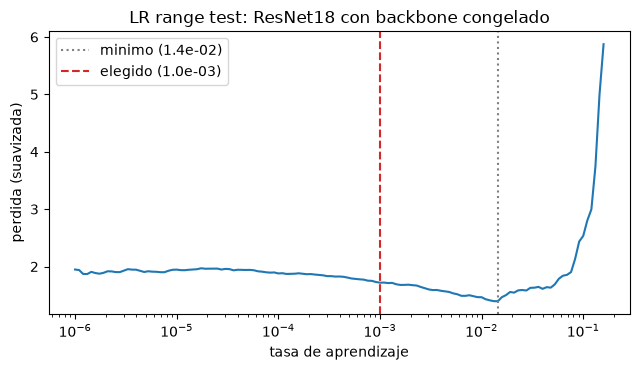

In [27]:
def lr_range_test(model_fn, loader, lr_min=1e-6, lr_max=1.0, steps=150, beta=0.9):
    seed_everything()
    model = model_fn().to(device)
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr_min, weight_decay=1e-4)
    gamma = (lr_max / lr_min) ** (1 / steps)
    lrs, losses, avg, best, it = [], [], 0.0, float("inf"), iter(loader)
    model.train()
    for i in range(steps):
        try:
            xb_, yb_ = next(it)
        except StopIteration:
            it = iter(loader); xb_, yb_ = next(it)
        loss = CRITERION(model(xb_.to(device)), yb_.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
        avg = beta * avg + (1 - beta) * loss.item()
        smooth = avg / (1 - beta ** (i + 1))
        lrs.append(opt.param_groups[0]["lr"]); losses.append(smooth)
        best = min(best, smooth)
        if smooth > 4 * best:
            break
        for g in opt.param_groups:
            g["lr"] *= gamma
    return np.array(lrs), np.array(losses)

lrs, losses = lr_range_test(TransferNet, loaders_tl["train"])
lr_at_min = lrs[np.argmin(losses)]
LR_HEAD = float(f"{lr_at_min / 10:.0e}")  # un orden de magnitud bajo el minimo, a 1 cifra significativa
print(f"Minimo de la perdida en lr = {lr_at_min:.2e}  ->  LR elegido para la cabeza: {LR_HEAD:.1e}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(lrs, losses)
ax.axvline(lr_at_min, ls=":", c="gray", label=f"minimo ({lr_at_min:.1e})")
ax.axvline(LR_HEAD, ls="--", c="C3", label=f"elegido ({LR_HEAD:.1e})")
ax.set_xlabel("tasa de aprendizaje"); ax.set_ylabel("perdida (suavizada)")
ax.set_title("LR range test: ResNet18 con backbone congelado"); ax.legend()
plt.tight_layout(); savefig("cp7_lr_range_test"); plt.show()

## Checkpoint 8: Etapa 1, *linear probe* (backbone completamente congelado)

Acá solo se entrena la cabeza `Dropout -> Linear(512, 5)`, con el LR elegido en el Checkpoint 7. 

Este resultado mide cuánto sirven, sin modificarlas, las características genéricas de ImageNet para distinguir partes del cuerpo y la raqueta en pádel. 

Además de lo anterior, se deja la cabeza bien inicializada para la Etapa 2, ya que si se descongela el backbone con una cabeza aleatoria, sus gradientes grandes destruyen las características preentrenadas en las primeras iteraciones.

In [28]:
seed_everything()
model_probe = TransferNet().to(device).set_trainable([])
opt = torch.optim.AdamW(model_probe.head.parameters(), lr=LR_HEAD, weight_decay=1e-4)
hist_probe, best_ep_probe = fit(model_probe, opt, loaders_tl, max_epochs=100, patience=10, tag="etapa 1")

[etapa 1] ep001 train 1.559/0.327  valid 1.189/0.545  lr=1.0e-03
[etapa 1] ep005 train 1.077/0.570  valid 0.877/0.682  lr=1.0e-03
[etapa 1] ep010 train 1.013/0.599  valid 0.787/0.725  lr=1.0e-03
[etapa 1] ep015 train 0.996/0.603  valid 0.762/0.712  lr=1.0e-03
[etapa 1] ep020 train 0.999/0.604  valid 0.762/0.723  lr=1.0e-03
[etapa 1] ep025 train 0.981/0.614  valid 0.738/0.733  lr=1.0e-03
[etapa 1] ep030 train 0.981/0.617  valid 0.736/0.723  lr=1.0e-03
[etapa 1] ep035 train 0.972/0.626  valid 0.738/0.735  lr=1.0e-03
[etapa 1] ep040 train 0.980/0.609  valid 0.732/0.722  lr=1.0e-03
[etapa 1] ep045 train 0.997/0.612  valid 0.725/0.736  lr=1.0e-03
[etapa 1] parada temprana en la epoca 48 (sin mejora >= 0.0001 en 10 epocas)
[etapa 1] mejor epoca 38 | val_loss 0.7123 | 1253 s


## Checkpoint 9: Etapa 2, descongelamiento progresivo con tasas de aprendizaje discriminativas

Se parte del modelo de la Etapa 1 y se descongelan **`layer3` y `layer4`**. 

Solamente dejamos congelados a `stem`, `layer1` y `layer2`. Esto es para detección de bordes y texturas genéricas que ya sirven tal cual, y contienen solo el 6 % de los parámetros. Afinarlos con unas 3.300 muestras aportaría poco y aumentaría el riesgo de sobreajuste.

**LR discriminativas** (Howard & Ruder, 2018): cuanto más genérica es la capa, menos se mueve.

| Grupo | LR |
|---|---|
| Cabeza | `LR_HEAD` |
| `layer4` | `LR_HEAD / 10` |
| `layer3` | `LR_HEAD / 30` |

**Ablación:** Un *fine-tuning* completo, con todos los bloques descongelados y LR = `LR_HEAD / 10` uniforme, parte de la misma cabeza de la Etapa 1.

In [29]:
def finetune(stages, lrs_by_group, tag, max_epochs=60, patience=10):
    seed_everything()
    model = TransferNet().to(device)
    model.load_state_dict(model_probe.state_dict())  # parte de la cabeza ya entrenada en la Etapa 1
    model.set_trainable(stages)
    groups = [dict(params=model.blocks[s].parameters(), lr=lrs_by_group[s]) for s in stages]
    groups.append(dict(params=model.head.parameters(), lr=lrs_by_group["head"]))
    opt = torch.optim.AdamW(groups, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max_epochs)
    t, tr, tot = param_table(model)
    print(f"[{tag}] parametros entrenables: {tr:,} / {tot:,} ({100 * tr / tot:.1f} %)")
    hist, best_ep = fit(model, opt, loaders_tl, max_epochs, patience, scheduler=sched, tag=tag)
    return model, hist, best_ep

model_ft, hist_ft, best_ep_ft = finetune(
    ["layer3", "layer4"], dict(layer3=LR_HEAD / 30, layer4=LR_HEAD / 10, head=LR_HEAD), tag="etapa 2")

model_full, hist_full, best_ep_full = finetune(
    STAGES, {**{s: LR_HEAD / 10 for s in STAGES}, "head": LR_HEAD / 10}, tag="ablacion: FT completo")

[etapa 2] parametros entrenables: 10,496,005 / 11,179,077 (93.9 %)
[etapa 2] ep001 train 1.078/0.612  valid 0.550/0.801  lr=1.0e-03
[etapa 2] ep005 train 0.501/0.810  valid 0.357/0.866  lr=9.9e-04
[etapa 2] ep010 train 0.342/0.874  valid 0.289/0.904  lr=9.5e-04
[etapa 2] ep015 train 0.279/0.893  valid 0.314/0.910  lr=8.7e-04
[etapa 2] ep020 train 0.213/0.919  valid 0.276/0.916  lr=7.7e-04
[etapa 2] ep025 train 0.208/0.923  valid 0.271/0.917  lr=6.5e-04
[etapa 2] ep030 train 0.201/0.920  valid 0.260/0.928  lr=5.3e-04
[etapa 2] ep035 train 0.151/0.937  valid 0.237/0.929  lr=4.0e-04
[etapa 2] ep040 train 0.142/0.950  valid 0.252/0.923  lr=2.7e-04
[etapa 2] ep045 train 0.138/0.950  valid 0.249/0.930  lr=1.7e-04
[etapa 2] parada temprana en la epoca 45 (sin mejora >= 0.0001 en 10 epocas)
[etapa 2] mejor epoca 35 | val_loss 0.2373 | 1105 s
[ablacion: FT completo] parametros entrenables: 11,179,077 / 11,179,077 (100.0 %)
[ablacion: FT completo] ep001 train 1.083/0.612  valid 0.452/0.852  lr=1

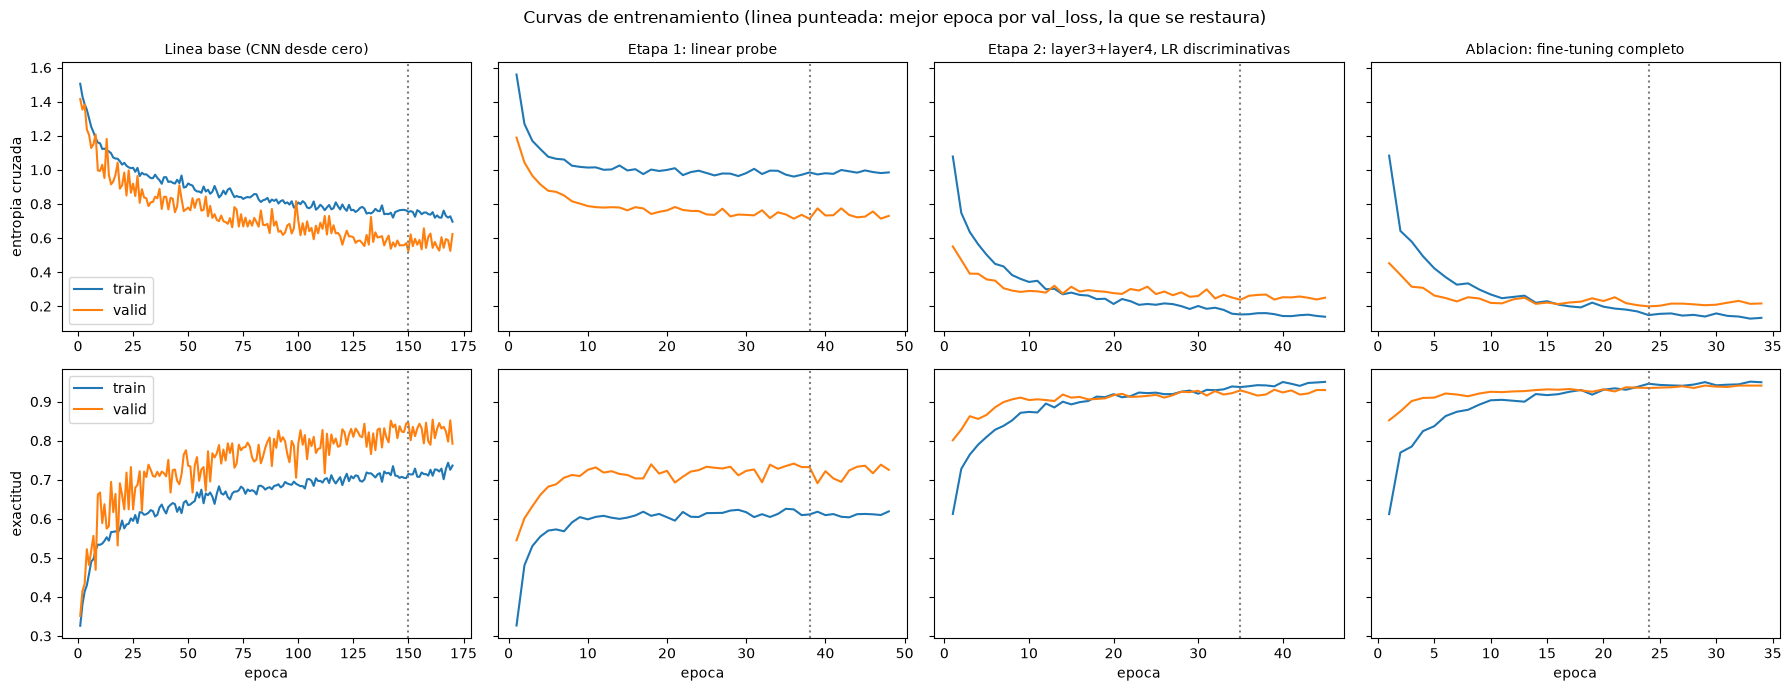

Hiperparametros (batch 64, entropia cruzada, parada temprana sobre val_loss):


,modelo,entrada,normalizacion,optimizador,lr,entrenables,mejor_epoca
0,Linea base,48x48,train,Adam,1e-3,24133,150
1,Etapa 1,112x112,ImageNet,AdamW wd=1e-4,1e-03,2565,38
2,Etapa 2,112x112,ImageNet,AdamW + coseno,1e-03 / 1e-04 / 3e-05,10496005,35
3,FT completo,112x112,ImageNet,AdamW + coseno,1e-04,11179077,24


In [30]:
# Curvas de convergencia cruzadas: perdida y exactitud, train vs valid, para los cuatro modelos
runs = [("Linea base (CNN desde cero)", hist_base, best_ep_base),
        ("Etapa 1: linear probe", hist_probe, best_ep_probe),
        ("Etapa 2: layer3+layer4, LR discriminativas", hist_ft, best_ep_ft),
        ("Ablacion: fine-tuning completo", hist_full, best_ep_full)]
fig, axes = plt.subplots(2, 4, figsize=(18, 7), sharey="row")
for j, (name, h, be) in enumerate(runs):
    axes[0, j].plot(h.epoch, h.train_loss, label="train"); axes[0, j].plot(h.epoch, h.val_loss, label="valid")
    axes[1, j].plot(h.epoch, h.train_acc, label="train"); axes[1, j].plot(h.epoch, h.val_acc, label="valid")
    for i in range(2):
        axes[i, j].axvline(be, ls=":", c="gray")
    axes[0, j].set_title(name, fontsize=10)
    axes[1, j].set_xlabel("epoca")
axes[0, 0].set_ylabel("entropia cruzada"); axes[1, 0].set_ylabel("exactitud")
axes[0, 0].legend(); axes[1, 0].legend()
fig.suptitle("Curvas de entrenamiento (linea punteada: mejor epoca por val_loss, la que se restaura)")
plt.tight_layout(); savefig("cp9_curvas_entrenamiento"); plt.show()

hp = pd.DataFrame([
    dict(modelo="Linea base", entrada="48x48", normalizacion="train", optimizador="Adam", lr="1e-3",
         entrenables=sum(p.numel() for p in model_base.parameters()), mejor_epoca=best_ep_base),
    dict(modelo="Etapa 1", entrada="112x112", normalizacion="ImageNet", optimizador="AdamW wd=1e-4",
         lr=f"{LR_HEAD:.0e}", entrenables=param_table(model_probe)[1], mejor_epoca=best_ep_probe),
    dict(modelo="Etapa 2", entrada="112x112", normalizacion="ImageNet", optimizador="AdamW + coseno",
         lr=f"{LR_HEAD:.0e} / {LR_HEAD/10:.0e} / {LR_HEAD/30:.0e}", entrenables=param_table(model_ft)[1],
         mejor_epoca=best_ep_ft),
    dict(modelo="FT completo", entrada="112x112", normalizacion="ImageNet", optimizador="AdamW + coseno",
         lr=f"{LR_HEAD/10:.0e}", entrenables=param_table(model_full)[1], mejor_epoca=best_ep_full),
])
print("Hiperparametros (batch 64, entropia cruzada, parada temprana sobre val_loss):")
hp

## Checkpoint 10: Evaluación en el conjunto de prueba

Acá es la única vez que se usa *test*. Para cada modelo se reportan:

- **Métricas globales:** Exactitud, y Precision, Recall y F1 en promedio *macro*.
- **Incertidumbre:** Intervalo de confianza del 95% para la exactitud, por *bootstrap* (2.000 remuestreos).
- **Desglose:** métricas por clase y matrices de confusión anotadas.

Para saber si la diferencia frente a la línea base es real o ruido de muestreo, se aplica la **prueba de McNemar** que es exacta y binomial y que compara los aciertos de los dos modelos **sobre las mismas muestras**.

In [31]:
# Predicciones sobre el conjunto de test y calculo de metricas: exactitud, precision, recall, f1 y CI95 para la exactitud
def predict(model, loader):
    model.eval()
    preds, ys = [], []
    with torch.no_grad():
        for xb_, yb_ in loader:
            preds.append(model(xb_.to(device)).argmax(1).cpu())
            ys.append(yb_)
    return torch.cat(ys).numpy(), torch.cat(preds).numpy()

def bootstrap_ci(y, p, n=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n, len(y)))
    accs = (y[idx] == p[idx]).mean(1)
    return np.percentile(accs, [2.5, 97.5])

models = {"Linea base (CNN desde cero)": (model_base, loaders_base),
          "Etapa 1: linear probe": (model_probe, loaders_tl),
          "Etapa 2: layer3+layer4": (model_ft, loaders_tl),
          "Ablacion: FT completo": (model_full, loaders_tl)}
y_test, preds = None, {}
for name, (m, ld) in models.items():
    y, p = predict(m, ld["test"])
    y_test = y if y_test is None else y_test
    assert (y == y_test).all()
    preds[name] = p

maj = Counter(kpt_df[kpt_df.split == "train"].label).most_common(1)[0][0]
rows = [dict(modelo="Clase mayoritaria", exactitud=(y_test == maj).mean(), ic95="-",
             precision_macro=np.nan, recall_macro=np.nan, f1_macro=np.nan)]
for name, p in preds.items():
    pr, rc, f1, _ = precision_recall_fscore_support(y_test, p, average="macro", zero_division=0)
    lo, hi = bootstrap_ci(y_test, p)
    rows.append(dict(modelo=name, exactitud=accuracy_score(y_test, p), ic95=f"[{lo:.3f}, {hi:.3f}]",
                     precision_macro=pr, recall_macro=rc, f1_macro=f1))
results = pd.DataFrame(rows)
results.to_csv(ROOT / "report" / "transfer_learning_resultados.csv", index=False)
print(f"Test: {len(y_test)} parches de {kpt_df[kpt_df.split == 'test'].rally_id.nunique()} rallies no vistos")
results.round(3)

Test: 1045 parches de 6 rallies no vistos


,modelo,exactitud,ic95,precision_macro,recall_macro,f1_macro
0,Clase mayoritaria,0.211,-,NaN,NaN,NaN
1,Linea base (CNN desde cero),0.857,"[0.836, 0.879]",0.860,0.855,0.854
2,Etapa 1: linear probe,0.773,"[0.748, 0.799]",0.769,0.771,0.769
3,Etapa 2: layer3+layer4,0.961,"[0.948, 0.972]",0.961,0.960,0.960
4,Ablacion: FT completo,0.963,"[0.950, 0.974]",0.962,0.962,0.962


In [32]:
# Metricas por clase: linea base vs. mejor modelo de transfer learning (por F1 macro en test)
tl_names = [n for n in preds if not n.startswith("Linea")]
BEST = max(tl_names, key=lambda n: results.set_index("modelo").loc[n, "f1_macro"])
print("Mejor modelo de transfer learning:", BEST, "\n")

per_class = []
for name in ["Linea base (CNN desde cero)", BEST]:
    pr, rc, f1, sup = precision_recall_fscore_support(y_test, preds[name], labels=range(N_CLASSES), zero_division=0)
    for k in range(N_CLASSES):
        per_class.append(dict(modelo="linea base" if name.startswith("Linea") else "transfer",
                              clase=KP_NAMES[k], precision=pr[k], recall=rc[k], f1=f1[k], soporte=sup[k]))
per_class = pd.DataFrame(per_class).pivot(index="clase", columns="modelo",
                                          values=["precision", "recall", "f1"]).loc[KP_NAMES]
per_class[("f1", "delta")] = per_class[("f1", "transfer")] - per_class[("f1", "linea base")]
print(per_class.round(3))
print("\nReporte completo del mejor modelo:")
print(classification_report(y_test, preds[BEST], target_names=KP_NAMES, digits=3))

Mejor modelo de transfer learning: Ablacion: FT completo 

         precision              recall                  f1                
modelo  linea base transfer linea base transfer linea base transfer  delta
clase                                                                     
hombro       0.791    0.968      0.959    0.986      0.867    0.977  0.111
codo         0.818    0.957      0.748    0.948      0.781    0.952  0.171
muneca       0.879    0.923      0.721    0.950      0.792    0.936  0.144
raqueta      0.864    0.974      0.873    0.934      0.869    0.953  0.085
cabeza       0.947    0.991      0.973    0.991      0.960    0.991  0.031

Reporte completo del mejor modelo:
              precision    recall  f1-score   support

      hombro      0.968     0.986     0.977       217
        codo      0.957     0.948     0.952       210
      muneca      0.923     0.950     0.936       201
     raqueta      0.974     0.934     0.953       197
      cabeza      0.991     0.991 

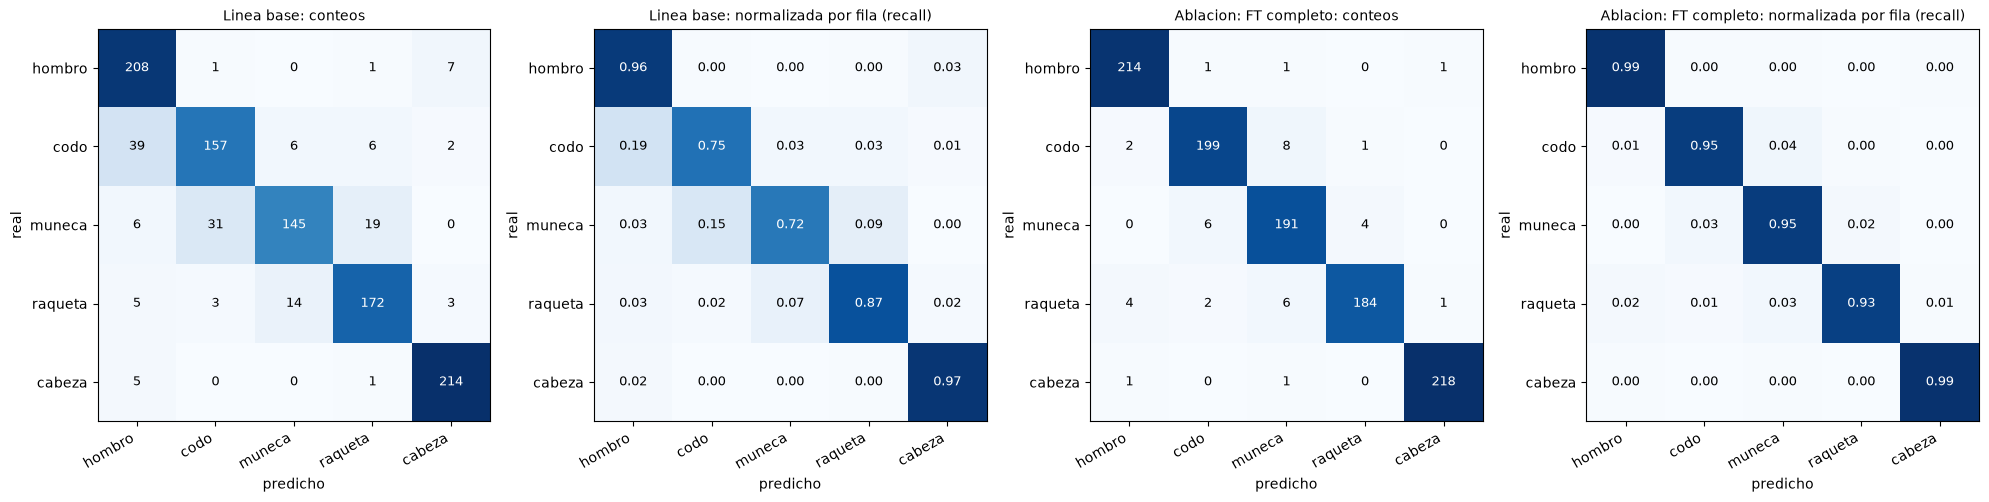

McNemar linea base vs Etapa 1: linear probe: transfer acierta y base falla = 65, al reves = 153, p = 2.33e-09
McNemar linea base vs Etapa 2: layer3+layer4: transfer acierta y base falla = 122, al reves = 14, p = 1.10e-22
McNemar linea base vs Ablacion: FT completo: transfer acierta y base falla = 123, al reves = 13, p = 1.24e-23


In [33]:
# Matrices de confusion: conteos y normalizadas por fila (recall)
def plot_cm(ax, y, p, title, normalize=False):
    cm = confusion_matrix(y, p, labels=range(N_CLASSES))
    show = cm / cm.sum(1, keepdims=True) if normalize else cm
    im = ax.imshow(show, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    ax.set_xticks(range(N_CLASSES)); ax.set_xticklabels(KP_NAMES, rotation=30, ha="right")
    ax.set_yticks(range(N_CLASSES)); ax.set_yticklabels(KP_NAMES)
    ax.set_xlabel("predicho"); ax.set_ylabel("real"); ax.set_title(title, fontsize=10)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            txt = f"{show[i, j]:.2f}" if normalize else str(cm[i, j])
            ax.text(j, i, txt, ha="center", va="center", fontsize=9,
                    color="white" if show[i, j] > show.max() / 2 else "black")
    return cm

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
plot_cm(axes[0], y_test, preds["Linea base (CNN desde cero)"], "Linea base: conteos")
plot_cm(axes[1], y_test, preds["Linea base (CNN desde cero)"], "Linea base: normalizada por fila (recall)", True)
plot_cm(axes[2], y_test, preds[BEST], f"{BEST}: conteos")
plot_cm(axes[3], y_test, preds[BEST], f"{BEST}: normalizada por fila (recall)", True)
plt.tight_layout(); savefig("cp10_matrices_confusion"); plt.show()

# McNemar exacto: solo cuentan los parches donde los modelos discrepan
a = preds["Linea base (CNN desde cero)"] == y_test
for name in tl_names:
    b = preds[name] == y_test
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    pval = binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    print(f"McNemar linea base vs {name}: transfer acierta y base falla = {n01}, al reves = {n10}, p = {pval:.2e}")

## Checkpoint 11: Análisis de errores

Para el análisis de errores, nos planteamos 3 preguntas:

1. **¿Qué pares de clases se confunden, y en qué dirección?**
2. **¿El error depende del tamaño del jugador?**
3. **¿En qué mira el modelo cuando falla?** Grad-CAM sobre `layer4`.

In [34]:
test_kpt = kpt_df[kpt_df.split == "test"].reset_index(drop=True)
cm_best = confusion_matrix(y_test, preds[BEST], labels=range(N_CLASSES))
cm_base = confusion_matrix(y_test, preds["Linea base (CNN desde cero)"], labels=range(N_CLASSES))
pairs = [dict(real=KP_NAMES[i], predicho=KP_NAMES[j], linea_base=int(cm_base[i, j]), transfer=int(cm_best[i, j]))
         for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j]
pairs = pd.DataFrame(pairs).sort_values("transfer", ascending=False)
print("Confusiones mas frecuentes (test):")
print(pairs.head(8).to_string(index=False))
print(f"\nErrores totales: linea base {int((preds['Linea base (CNN desde cero)'] != y_test).sum())} | "
      f"transfer {int((preds[BEST] != y_test).sum())} de {len(y_test)}")

# Exactitud por tamano del jugador (terciles del alto del bbox en pixeles)
test_kpt["alto_px"] = test_kpt.bbox_h * 640
test_kpt["tamano"] = pd.qcut(test_kpt.alto_px, 3, labels=["lejano", "medio", "cercano"])
test_kpt["ok_base"] = preds["Linea base (CNN desde cero)"] == y_test
test_kpt["ok_tl"] = preds[BEST] == y_test
by_size = test_kpt.groupby("tamano", observed=True).agg(
    alto_px=("alto_px", "median"), n=("label", "size"), linea_base=("ok_base", "mean"), transfer=("ok_tl", "mean"))
print("\nExactitud por tamano del jugador:")
print(by_size.round(3))

Confusiones mas frecuentes (test):
   real predicho  linea_base  transfer
   codo   muneca           6         8
 muneca     codo          31         6
raqueta   muneca          14         6
 muneca  raqueta          19         4
raqueta   hombro           5         4
raqueta     codo           3         2
   codo   hombro          39         2
 hombro     codo           1         1

Errores totales: linea base 149 | transfer 39 de 1045

Exactitud por tamano del jugador:
         alto_px    n  linea_base  transfer
tamano                                     
lejano      46.0  363       0.851     0.945
medio       94.0  349       0.819     0.971
cercano    110.0  333       0.904     0.973


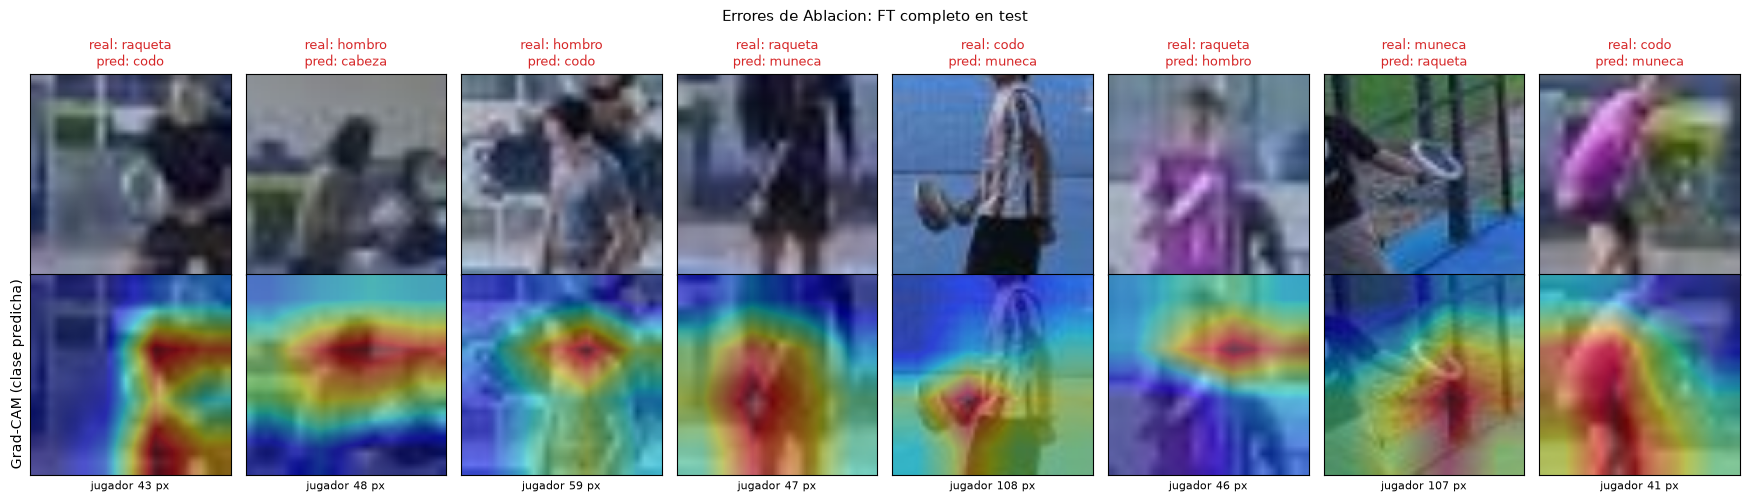

In [35]:
class GradCAM:
    """Grad-CAM sobre la salida de layer4."""
    def __init__(self, model):
        self.model, self.acts, self.grads = model, None, None
        layer = model.blocks["layer4"]
        layer.register_forward_hook(lambda m, i, o: setattr(self, "acts", o))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, "grads", go[0]))

    def __call__(self, x, cls):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        out = self.model(x)
        self.model.zero_grad(); out[0, cls].backward()
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        return (cam / (cam.max() + 1e-8)).detach().cpu().numpy()

cam = GradCAM(models[BEST][0])
test_ds = loaders_tl["test"].dataset
wrong = np.where(preds[BEST] != y_test)[0]
show = np.random.default_rng(SEED).choice(wrong, size=min(8, len(wrong)), replace=False)
fig, axes = plt.subplots(2, len(show), figsize=(2.2 * len(show), 5))
for j, i in enumerate(show):
    row = test_kpt.iloc[i]
    patch = np.asarray(crop_patch(row, 112))
    heat = cam(test_ds[i][0], int(preds[BEST][i]))
    axes[0, j].imshow(patch)
    axes[0, j].set_title(f"real: {KP_NAMES[y_test[i]]}\npred: {KP_NAMES[preds[BEST][i]]}", fontsize=9, color="C3")
    axes[1, j].imshow(patch); axes[1, j].imshow(heat, cmap="jet", alpha=0.45)
    axes[1, j].set_xlabel(f"jugador {row.bbox_h * 640:.0f} px", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[1, 0].set_ylabel("Grad-CAM (clase predicha)")
plt.suptitle(f"Errores de {BEST} en test", fontsize=11)
plt.tight_layout(); savefig("cp11_errores_gradcam"); plt.show()

## Checkpoint 12: Resultado complementario, *transfer learning* para regresión de keypoints (Unidad 2)

Para dejar en un solo lugar todo el *transfer learning* del proyecto, se reproduce de forma compacta el experimento de la Unidad 2. Un ResNet18 de ImageNet, congelado salvo `layer4`, con una cabeza `Linear(512, 10) + Sigmoid`, regresa las coordenadas (x, y) de los 5 keypoints dentro del recorte del jugador. Se compara con la misma CNN desde cero de la Unidad 2.

- **Pérdida:** *SmoothL1* Enmascarada. Los ejes sin anotación no penalizan.
- **Métrica:** Error absoluto medio en píxeles de un recorte de 128×192.
- **Datos:** Recortes y partición de `data/processed/manifest_keypoints.csv`, por rally.

In [36]:
# Regresion de keypoints: dataset, modelo y entrenamiento
manifest = pd.read_csv(PROC / "manifest_keypoints.csv")
manifest["crop_path"] = manifest.crop_path.map(lambda p: str(PROC / "crops_kpts" / Path(p).parent.name / Path(p).name))
KP_COLS, MASK_COLS, REG_SIZE = [f"kp_{i}" for i in range(10)], [f"mask_{i}" for i in range(10)], (128, 192)

class CropRegDataset(Dataset):
    def __init__(self, frame, mean, std, train=False):
        self.f, self.train = frame.reset_index(drop=True), train
        self.mean, self.std = np.array(mean, np.float32), np.array(std, np.float32)
    def __len__(self):
        return len(self.f)
    def __getitem__(self, i):
        r = self.f.iloc[i]
        arr = np.asarray(Image.open(r.crop_path).convert("RGB").resize(REG_SIZE, Image.BILINEAR), np.float32) / 255
        kp, mk = r[KP_COLS].values.astype(np.float32).copy(), r[MASK_COLS].values.astype(np.float32)
        if self.train and random.random() < 0.5:
            arr = arr[:, ::-1].copy(); kp[0::2] = 1 - kp[0::2]
        arr = ((arr - self.mean) / self.std).transpose(2, 0, 1)
        return torch.from_numpy(arr.copy()), torch.from_numpy(kp), torch.from_numpy(mk)

def masked_smoothl1(pred, target, mask):
    return (F.smooth_l1_loss(pred, target, reduction="none") * mask).sum() / mask.sum().clamp(min=1)

def reg_loaders(mean, std):
    return {s: DataLoader(CropRegDataset(manifest[manifest.split == s], mean, std, s == "train"), 32,
                          shuffle=s == "train", generator=torch.Generator().manual_seed(SEED)) for s in ["train", "valid", "test"]}

def fit_reg(model, lr, loaders, max_epochs=300, patience=20):
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    best, ref, stale = (float("inf"), None, 0), float("inf"), 0
    for ep in range(1, max_epochs + 1):
        for split in ["train", "valid"]:
            model.train(split == "train"); tot, n = 0.0, 0
            with torch.set_grad_enabled(split == "train"):
                for xb_, kb, mb in loaders[split]:
                    xb_, kb, mb = xb_.to(device), kb.to(device), mb.to(device)
                    loss = masked_smoothl1(model(xb_), kb, mb)
                    if split == "train":
                        opt.zero_grad(); loss.backward(); opt.step()
                    tot += loss.item() * len(xb_); n += len(xb_)
        va = tot / n
        if va < best[0]:
            best = (va, copy.deepcopy(model.state_dict()), ep)
        if ref - va >= 1e-4: ref, stale = va, 0
        else: stale += 1
        if stale >= patience:
            break
    model.load_state_dict(best[1])
    return best[2]

class CNNRegressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, 10), nn.Sigmoid())
    def forward(self, x):
        return self.head(self.features(x))

_trm = manifest[manifest.split == "train"].sample(300, random_state=SEED)
_px = np.stack([np.asarray(Image.open(p).convert("RGB").resize(REG_SIZE), np.float32) / 255 for p in _trm.crop_path])
reg_mean, reg_std = _px.reshape(-1, 3).mean(0), _px.reshape(-1, 3).std(0)

seed_everything()
reg_scratch = CNNRegressor().to(device)
ep_a = fit_reg(reg_scratch, 1e-3, reg_loaders(reg_mean, reg_std))

seed_everything()
reg_tl = TransferNet(n_classes=10).to(device).set_trainable(["layer4"])
reg_tl.head = nn.Sequential(nn.Flatten(), nn.Linear(512, 10), nn.Sigmoid()).to(device)
ep_b = fit_reg(reg_tl, 1e-3, reg_loaders(IMAGENET_MEAN, IMAGENET_STD))

def reg_errors(model, loader):
    model.eval(); errs = {k: [] for k in range(5)}
    with torch.no_grad():
        for xb_, kb, mb in loader:
            pr = model(xb_.to(device)).cpu().numpy(); kb, mb = kb.numpy(), mb.numpy()
            for k in range(5):
                for ax_, size in ((0, REG_SIZE[0]), (1, REG_SIZE[1])):
                    sel = mb[:, 2 * k + ax_] > 0
                    errs[k] += list(np.abs(pr[sel, 2 * k + ax_] - kb[sel, 2 * k + ax_]) * size)
    return [np.mean(errs[k]) for k in range(5)]

reg_table = pd.DataFrame({"keypoint": KP_NAMES,
                          "CNN desde cero (px)": reg_errors(reg_scratch, reg_loaders(reg_mean, reg_std)["test"]),
                          "ResNet18 transfer (px)": reg_errors(reg_tl, reg_loaders(IMAGENET_MEAN, IMAGENET_STD)["test"])})
reg_table["mejora %"] = 100 * (1 - reg_table["ResNet18 transfer (px)"] / reg_table["CNN desde cero (px)"])
print(f"Mejores epocas: CNN desde cero {ep_a} | ResNet18 {ep_b}")
reg_table.round(2)

Mejores epocas: CNN desde cero 77 | ResNet18 19


,keypoint,CNN desde cero (px),ResNet18 transfer (px),mejora %
0,hombro,6.52,5.24,19.590000
1,codo,8.25,6.61,19.930000
2,muneca,8.23,6.56,20.389999
3,raqueta,13.63,9.64,29.260000
4,cabeza,5.54,3.62,34.619999


## Checkpoint 13: Conclusiones y decisiones justificadas

In [37]:
r = results.set_index("modelo")
base_acc, best_acc = r.loc["Linea base (CNN desde cero)", "exactitud"], r.loc[BEST, "exactitud"]
base_f1, best_f1 = r.loc["Linea base (CNN desde cero)", "f1_macro"], r.loc[BEST, "f1_macro"]
top = pairs.iloc[0]
print(f"""
1. Transfer learning vs. linea base: {BEST} alcanza exactitud {best_acc:.3f} (F1 macro {best_f1:.3f})
   frente a {base_acc:.3f} ({base_f1:.3f}) de la CNN desde cero: {100 * (best_acc - base_acc):+.1f} puntos,
   sobre {len(y_test)} parches de rallies no vistos (ver McNemar arriba).
2. Linear probe: {r.loc['Etapa 1: linear probe', 'exactitud']:.3f}. Las caracteristicas de ImageNet sin
   adaptar ya separan bien las clases, pero ajustar layer3/layer4 aporta la diferencia restante.
3. Congelamiento parcial vs. FT completo: {r.loc['Etapa 2: layer3+layer4', 'exactitud']:.3f} vs.
   {r.loc['Ablacion: FT completo', 'exactitud']:.3f}.
4. Confusion sistematica principal: {top.real} -> {top.predicho} ({top.transfer} casos en transfer,
   {top.linea_base} en la linea base).
5. Exactitud por tamano del jugador (transfer): {', '.join(f'{k}={v:.2f}' for k, v in by_size.transfer.items())}.
6. Regresion (anexo): ResNet18 reduce el error medio de {reg_table['CNN desde cero (px)'].mean():.2f} a
   {reg_table['ResNet18 transfer (px)'].mean():.2f} px.
""")


1. Transfer learning vs. linea base: Ablacion: FT completo alcanza exactitud 0.963 (F1 macro 0.962)
   frente a 0.857 (0.854) de la CNN desde cero: +10.5 puntos,
   sobre 1045 parches de rallies no vistos (ver McNemar arriba).
2. Linear probe: 0.773. Las caracteristicas de ImageNet sin
   adaptar ya separan bien las clases, pero ajustar layer3/layer4 aporta la diferencia restante.
3. Congelamiento parcial vs. FT completo: 0.961 vs.
   0.963.
4. Confusion sistematica principal: codo -> muneca (8 casos en transfer,
   6 en la linea base).
5. Exactitud por tamano del jugador (transfer): lejano=0.94, medio=0.97, cercano=0.97.
6. Regresion (anexo): ResNet18 reduce el error medio de 8.44 a
   6.33 px.



**Limitaciones:**
- **Diversidad de los datos:** El dataset tiene 335 imágenes de unos 35 rallies, de una misma cancha y una misma cámara. La partición realizada, por rally, evita la fuga, pero *test* sigue siendo la misma escena. Por esto mismo el desempeño fuera de esta cancha, con alguna otra cámara, o iluminación o cncha, no está medido, y es probable que sea menor.
- **Información local:** La clasificación usa solo el parche local. Las confusiones entre partes del cuerpo vecinas reflejan esa falta de contexto. Agregar la posición relativa dentro del bbox del jugador, o clasificar los 5 puntos de forma conjunta, debería reducirlas.
- **Selección del LR:** El LR se fijó con un único *LR range test*, sin búsqueda de hiperparámetros con validación cruzada por rally. Es una decisión razonable para un prototipo, pero no es óptima.